# Creating Figures of the Durable Model

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import copy
import time
import datetime
from pathlib import Path

start_time = time.time()

from DurableModel import DurableConsumer

FIG_DIR = Path("../Figures/DurableModel")
FIG_DIR.mkdir(parents=True, exist_ok=True)

# Line styles matching Figures.ipynb
LINE_STYLES = [
    ("k", "-"),
    ("r", "-"),
    ("k", "--"),
    ("k", ":"),
]


def channel_title(sigma_xi, SearchCost, PriceShkStd, extra=None):
    """Parameter header in the style of Figures.ipynb."""
    s = (
        rf"$\sigma_{{\xi}} = {sigma_xi}$, "
        rf"$S = {SearchCost}$, "
        rf"$\sigma_{{p}} = {PriceShkStd}$"
    )
    if extra:
        s = s + ", " + extra
    return s


def plot_adjuster_policies(models, labels, t, title, fname_prefix, x_max=None):
    """Overlay adjuster c(ℓ) and d(ℓ); save two PDFs."""
    # Non-durable
    fig, ax = plt.subplots(figsize=(6.5, 4.5))
    for model, lab, (color, ls) in zip(models, labels, LINE_STYLES):
        sol = model.solution[t]
        x = model.xNrmGrid
        if x_max is not None:
            x = x[x <= x_max]
        ax.plot(x, sol.cFuncAdj_1d(x), color=color, linestyle=ls, label=lab)
    ax.set_xlabel(r"Liquidity, $\ell_t$")
    ax.set_ylabel(r"Non-durable consumption, $c^{adj}(\ell_t)$")
    ax.set_title(title)
    ax.grid(color="k", linestyle=":", linewidth=0.5)
    ax.legend(loc=4)
    fig.tight_layout()
    fig.savefig(FIG_DIR / f"{fname_prefix}_cAdj.pdf", dpi=150)
    plt.show()

    # Durable
    fig, ax = plt.subplots(figsize=(6.5, 4.5))
    for model, lab, (color, ls) in zip(models, labels, LINE_STYLES):
        sol = model.solution[t]
        x = model.xNrmGrid
        if x_max is not None:
            x = x[x <= x_max]
        ax.plot(x, sol.dFuncAdj_1d(x), color=color, linestyle=ls, label=lab)
    ax.set_xlabel(r"Liquidity, $\ell_t$")
    ax.set_ylabel(r"Durable consumption, $d^{adj}(\ell_t)$")
    ax.set_title(title)
    ax.grid(color="k", linestyle=":", linewidth=0.5)
    ax.legend(loc=4)
    fig.tight_layout()
    fig.savefig(FIG_DIR / f"{fname_prefix}_dAdj.pdf", dpi=150)
    plt.show()


def plot_ss_heatmaps(models, panel_titles, t, fname, suptitle=None):
    """2x2 (or 1) S,s / adjusting heatmaps; viridis as in Combined notebook."""
    n = len(models)
    if n == 1:
        fig, axes = plt.subplots(1, 1, figsize=(6.0, 4.5))
        axes = np.array([axes])
    else:
        nrows = 2
        ncols = 2
        fig, axes = plt.subplots(nrows, ncols, figsize=(10, 8), sharex=True, sharey=True)
        axes = axes.ravel()

    last_pcm = None
    for ax, model, ptitle in zip(axes, models, panel_titles):
        sol = model.solution[t]
        last_pcm = ax.pcolormesh(
            sol.mNrmGrid,
            sol.nNrmGrid,
            sol.adjusting_arr,
            cmap="viridis",
            shading="auto",
            vmin=0.0,
            vmax=1.0,
        )
        ax.set_title(ptitle)
        ax.set_xlabel(r"Market resources, $m_t$")
        ax.set_ylabel(r"Durable stock, $n_t$")

    for ax in axes[n:]:
        ax.set_visible(False)

    if suptitle:
        fig.suptitle(suptitle, y=0.98)
    # Leave room at the bottom for a colorbar below the x-axis labels
    fig.tight_layout(rect=[0.0, 0.14, 1.0, 0.96 if suptitle else 1.0])
    cbar_ax = fig.add_axes([0.2, 0.04, 0.6, 0.03])  # [left, bottom, width, height]
    fig.colorbar(
        last_pcm,
        cax=cbar_ax,
        orientation="horizontal",
        label=r"adjusting / $\mathbb{E}[\varepsilon^*]$",
    )
    fig.savefig(FIG_DIR / fname, dpi=150, bbox_inches="tight")
    plt.show()


def solve_variant(base, **overrides):
    params = copy.deepcopy(base)
    params.update(overrides)
    model = DurableConsumer(**params)
    model.solve()
    return model


In [2]:
### Parameters for all figures
T = 20 #(number of periods before terminal)
t = 19 #(period to plot)

In [3]:
### Baseline parameters for all models

durable_defaults = dict(
    CRRA=2.0,
    DiscFac=0.96,
    LivPrb=1.0,
    alpha=0.9,
    d_ubar=1e-4,
    dDepr=0.15,
    adjC=0.15,
    MaintCost=0.0,
    OpCost=0.0,
    Rfree=1.04,
    RSpread=0.0,
    PermGroFac=1.0,
    LTV=0.0,
    BoroCnstArt=0.0,
    # Channels
    sigma_xi=0.10,
    TasteShkCount=11,
    SearchCost=0.1,
    ScaleBool=False,
    e_grid_count=101,
    PriceShkCount=5,
    PriceShkStd=0.1,
    # Income
    PermShkStd=0.0,
    PermShkCount=1,
    TranShkStd=0.1,
    TranShkCount=7,
    UnempPrb=0.0,
    IncUnemp=0.0,
    IncUnemp_Std=0.1,
    truncation=2,
    taxrate=0.0,
    labor=1.0,
    wage=1.0,
    # EoP method
    use_expected=True,
    use_TransitionMatrix=False,
    # Grids
    nNrmMax=5.0,
    nNrmCount=40,
    mNrmMax=8.0,
    mNrmCount=50,
    xNrmMax=13.0,
    xNrmCount=80,
    aNrmMax=8.0,
    aNrmCount=50,
    NestFac=2,
    grid_type="exp_mult",
    TranMatrix_mCount=1010,
    TranMatrix_bCount=1000,
    N_scan=800,
    # Horizon: cycles = number of periods before terminal (1 => T and T-1)
    cycles=T,
    verbose=False,
)


### Baseline-model (no taste, search, price)
Plot:
- non-durable consumption function of adjuster
- durable consumption function of the adjuster
- Ss structure (similar to DurableModel_One_Period.ipynb)

In [4]:
Baseline_params = copy.deepcopy(durable_defaults)
Baseline_params["sigma_xi"] = 0.0
Baseline_params["SearchCost"] = 0.0
Baseline_params["PriceShkStd"] = 0.0
Baseline_params["TasteShkCount"] = 1
Baseline_params["PriceShkCount"] = 1

print("Solving baseline...")
t0 = time.time()
Baseline = DurableConsumer(**Baseline_params)
Baseline.solve()
print(f"Baseline done in {time.time() - t0:.1f}s")


Solving baseline...


c:\Users\adria\anaconda3\envs\DCEGM_Search_env\lib\site-packages\HARK\rewards.py:40: RuntimeWarning: divide by zero encountered in reciprocal
  return c ** (1.0 - rho) / (1.0 - rho)
c:\Users\adria\OneDrive - Johns Hopkins\Github\AMonninger\DCEGM_Search\Code\DurableModel.py:353: RuntimeWarning: divide by zero encountered in power
  * C ** (self.alpha * (1.0 - self.CRRA) - 1.0)
c:\Users\adria\OneDrive - Johns Hopkins\Github\AMonninger\DCEGM_Search\Code\DurableModel.py:360: RuntimeWarning: divide by zero encountered in power
  * (C ** (self.alpha * (1.0 - self.CRRA)))
c:\Users\adria\anaconda3\envs\DCEGM_Search_env\lib\site-packages\HARK\rewards.py:40: RuntimeWarning: divide by zero encountered in reciprocal
  return c ** (1.0 - rho) / (1.0 - rho)
c:\Users\adria\OneDrive - Johns Hopkins\Github\AMonninger\DCEGM_Search\Code\DurableModel.py:360: RuntimeWarning: divide by zero encountered in power
  * (C ** (self.alpha * (1.0 - self.CRRA)))
c:\Users\adria\OneDrive - Johns Hopkins\Github\AMonni

Baseline done in 13.1s


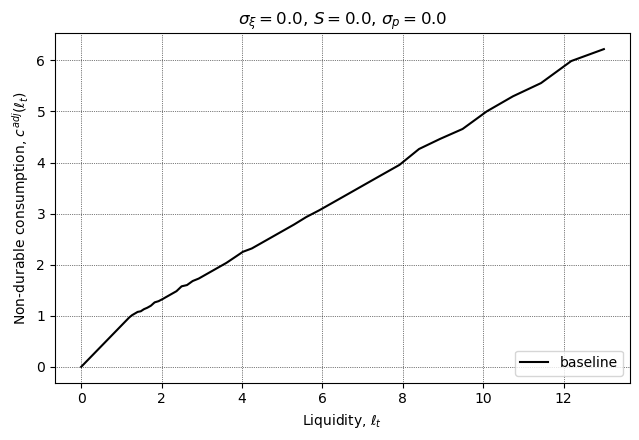

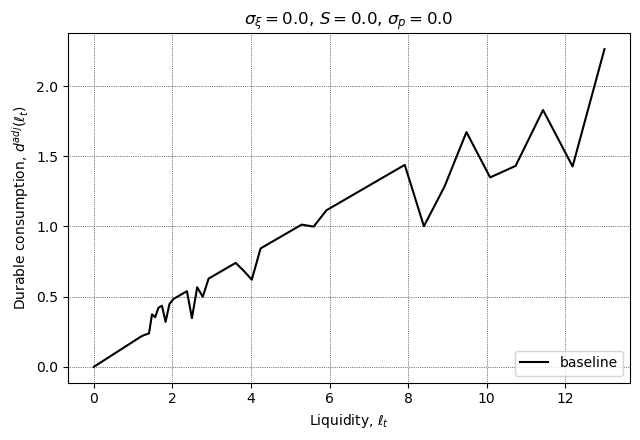

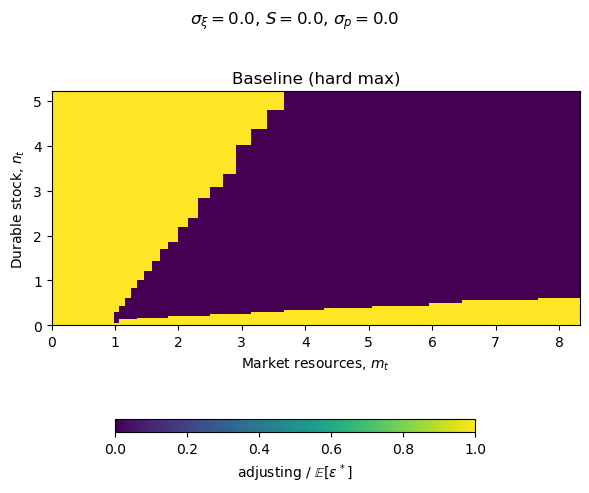

In [5]:
title = channel_title(0.0, 0.0, 0.0)
plot_adjuster_policies([Baseline], [r"baseline"], t, title, "Baseline")
plot_ss_heatmaps(
    [Baseline],
    [r"Baseline (hard max)"],
    t,
    "Baseline_Ss.pdf",
    suptitle=title,
)

### Baseline-model (no taste, search, price) with more shock points
- TranShkCount = 1, 7, 151
- TransitionMethod 

Plot:
- non-durable consumption function of adjuster (all 4 in one)
- durable consumption function of the adjuster (all 4 in one)
- Ss structure (similar to DurableModel_One_Period.ipynb) (4 subplots)

Solving TranShkCount=1 (expected)...


c:\Users\adria\anaconda3\envs\DCEGM_Search_env\lib\site-packages\HARK\rewards.py:40: RuntimeWarning: divide by zero encountered in reciprocal
  return c ** (1.0 - rho) / (1.0 - rho)
c:\Users\adria\OneDrive - Johns Hopkins\Github\AMonninger\DCEGM_Search\Code\DurableModel.py:353: RuntimeWarning: divide by zero encountered in power
  * C ** (self.alpha * (1.0 - self.CRRA) - 1.0)
c:\Users\adria\OneDrive - Johns Hopkins\Github\AMonninger\DCEGM_Search\Code\DurableModel.py:360: RuntimeWarning: divide by zero encountered in power
  * (C ** (self.alpha * (1.0 - self.CRRA)))


Solving TranShkCount=7 (expected)...
Solving TranShkCount=151 (expected)...
Solving TransitionMethod...


c:\Users\adria\anaconda3\envs\DCEGM_Search_env\lib\site-packages\HARK\rewards.py:40: RuntimeWarning: divide by zero encountered in reciprocal
  return c ** (1.0 - rho) / (1.0 - rho)
c:\Users\adria\OneDrive - Johns Hopkins\Github\AMonninger\DCEGM_Search\Code\DurableModel.py:353: RuntimeWarning: divide by zero encountered in power
  * C ** (self.alpha * (1.0 - self.CRRA) - 1.0)
c:\Users\adria\OneDrive - Johns Hopkins\Github\AMonninger\DCEGM_Search\Code\DurableModel.py:360: RuntimeWarning: divide by zero encountered in power
  * (C ** (self.alpha * (1.0 - self.CRRA)))


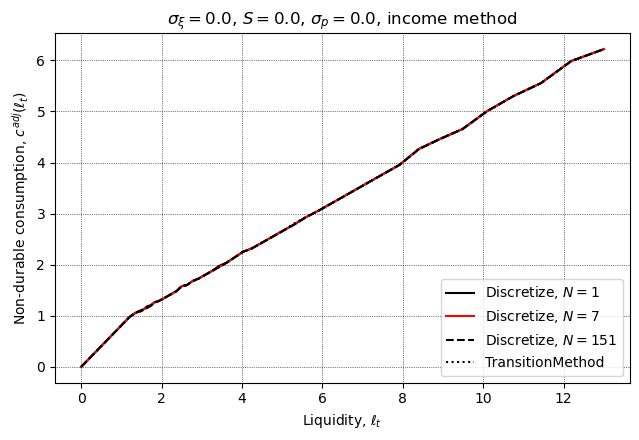

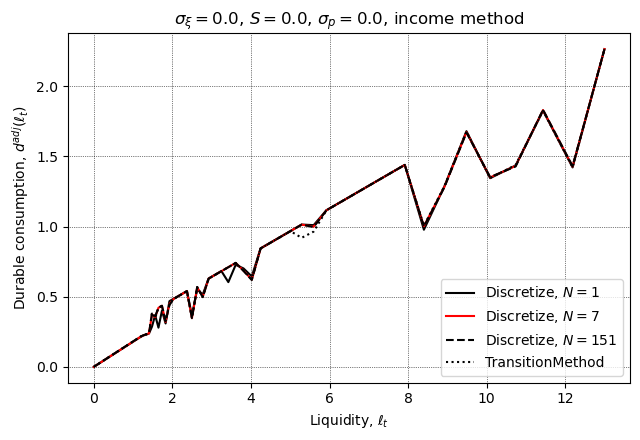

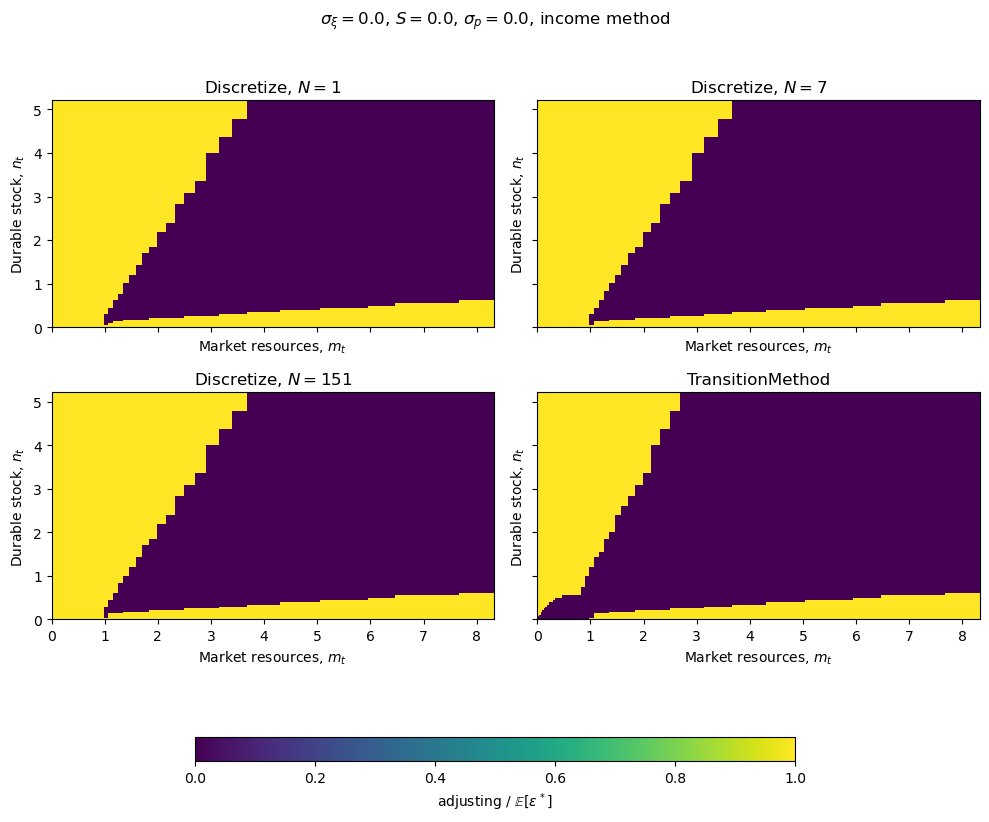

In [6]:
# Income discretization comparison (Figures_IncomeDiscMethod style):
# expected/Discretize with TranShkCount = 1, 7, 151 + TransitionMethod
base_inc = copy.deepcopy(durable_defaults)
base_inc["sigma_xi"] = 0.0
base_inc["SearchCost"] = 0.0
base_inc["PriceShkStd"] = 0.0
base_inc["TasteShkCount"] = 1
base_inc["PriceShkCount"] = 1

print("Solving TranShkCount=1 (expected)...")
Inc_1 = solve_variant(base_inc, TranShkCount=1, use_expected=True, use_TransitionMatrix=False)

print("Solving TranShkCount=7 (expected)...")
Inc_7 = solve_variant(base_inc, TranShkCount=7, use_expected=True, use_TransitionMatrix=False)

print("Solving TranShkCount=151 (expected)...")
Inc_151 = solve_variant(base_inc, TranShkCount=151, use_expected=True, use_TransitionMatrix=False)

print("Solving TransitionMethod...")
Inc_TM = solve_variant(
    base_inc,
    TranShkCount=7,
    use_expected=False,
    use_TransitionMatrix=True,
)

inc_models = [Inc_1, Inc_7, Inc_151, Inc_TM]
inc_labels = [
    r"Discretize, $N=1$",
    r"Discretize, $N=7$",
    r"Discretize, $N=151$",
    r"TransitionMethod",
]
inc_panels = [
    r"Discretize, $N=1$",
    r"Discretize, $N=7$",
    r"Discretize, $N=151$",
    r"TransitionMethod",
]

title = channel_title(0.0, 0.0, 0.0, extra=r"income method")
plot_adjuster_policies(inc_models, inc_labels, t, title, "IncomeDisc")
plot_ss_heatmaps(inc_models, inc_panels, t, "IncomeDisc_Ss.pdf", suptitle=title)


### TasteshockModel (no search, price)
- Tasteshock = 0, 0.05, 0.1, 0.2

Plot:
- non-durable consumption function of adjuster (all 4 in one)
- durable consumption function of the adjuster (all 4 in one)
- Ss structure (similar to DurableModel_One_Period.ipynb) (4 subplots)

Solving taste sigma_xi=0.0...


c:\Users\adria\anaconda3\envs\DCEGM_Search_env\lib\site-packages\HARK\rewards.py:40: RuntimeWarning: divide by zero encountered in reciprocal
  return c ** (1.0 - rho) / (1.0 - rho)
c:\Users\adria\OneDrive - Johns Hopkins\Github\AMonninger\DCEGM_Search\Code\DurableModel.py:353: RuntimeWarning: divide by zero encountered in power
  * C ** (self.alpha * (1.0 - self.CRRA) - 1.0)
c:\Users\adria\OneDrive - Johns Hopkins\Github\AMonninger\DCEGM_Search\Code\DurableModel.py:360: RuntimeWarning: divide by zero encountered in power
  * (C ** (self.alpha * (1.0 - self.CRRA)))


Solving taste sigma_xi=0.05...
Solving taste sigma_xi=0.1...
Solving taste sigma_xi=0.2...


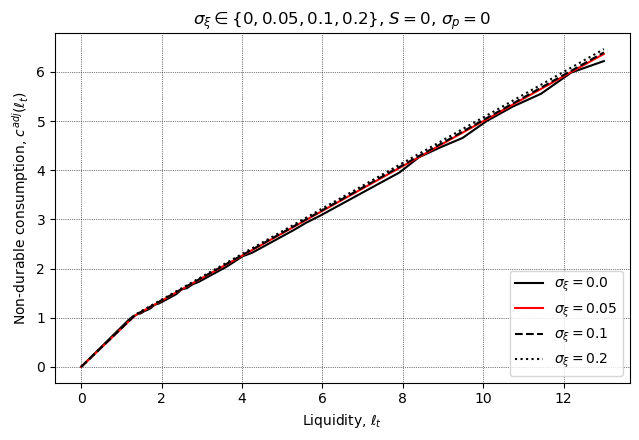

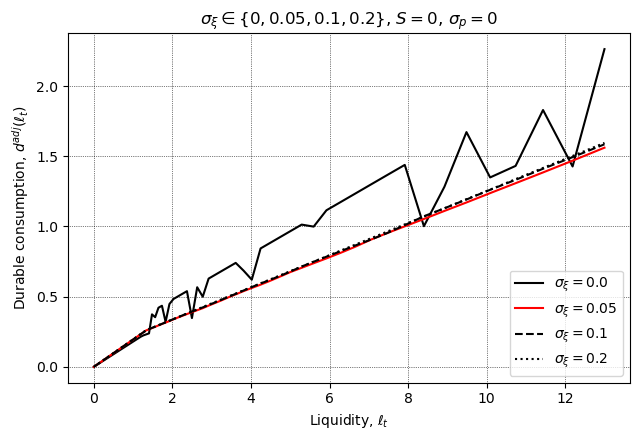

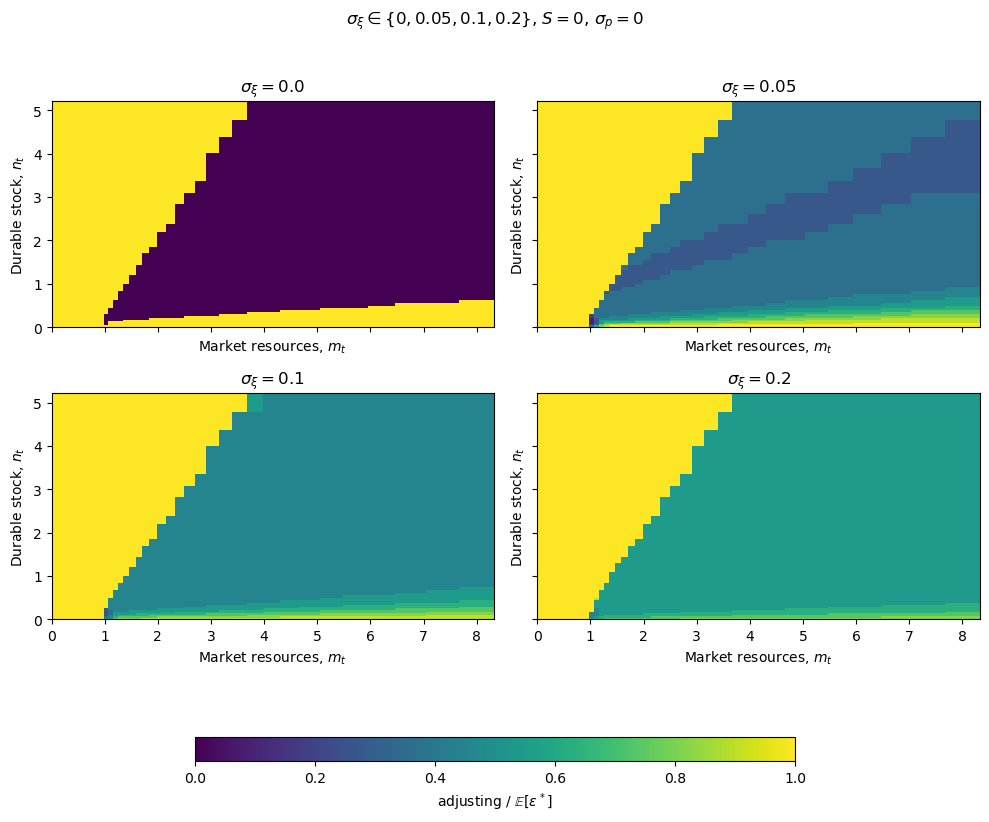

In [7]:
base_taste = copy.deepcopy(durable_defaults)
base_taste["SearchCost"] = 0.0
base_taste["PriceShkStd"] = 0.0
base_taste["PriceShkCount"] = 1

sigmas = [0.0, 0.05, 0.1, 0.2]
taste_models = []
for sx in sigmas:
    print(f"Solving taste sigma_xi={sx}...")
    taste_models.append(
        solve_variant(
            base_taste,
            sigma_xi=sx,
            TasteShkCount=1 if sx == 0.0 else base_taste["TasteShkCount"],
        )
    )

taste_labels = [rf"$\sigma_{{\xi}} = {sx}$" for sx in sigmas]
taste_panels = taste_labels
title = r"$\sigma_{\xi} \in \{0, 0.05, 0.1, 0.2\}$, $S = 0$, $\sigma_{p} = 0$"
plot_adjuster_policies(taste_models, taste_labels, t, title, "TasteShock")
plot_ss_heatmaps(taste_models, taste_panels, t, "TasteShock_Ss.pdf", suptitle=title)


### SearchModel (no tasteshock, price)
- Search = 0, 0.05, 0.1, 0.2

Plot:
- non-durable consumption function of adjuster (all 4 in one)
- durable consumption function of the adjuster (all 4 in one)
- Ss structure (similar to DurableModel_One_Period.ipynb) (4 subplots)

Solving SearchCost=0.0...


c:\Users\adria\anaconda3\envs\DCEGM_Search_env\lib\site-packages\HARK\rewards.py:40: RuntimeWarning: divide by zero encountered in reciprocal
  return c ** (1.0 - rho) / (1.0 - rho)
c:\Users\adria\OneDrive - Johns Hopkins\Github\AMonninger\DCEGM_Search\Code\DurableModel.py:353: RuntimeWarning: divide by zero encountered in power
  * C ** (self.alpha * (1.0 - self.CRRA) - 1.0)
c:\Users\adria\OneDrive - Johns Hopkins\Github\AMonninger\DCEGM_Search\Code\DurableModel.py:360: RuntimeWarning: divide by zero encountered in power
  * (C ** (self.alpha * (1.0 - self.CRRA)))


Solving SearchCost=0.05...


c:\Users\adria\OneDrive - Johns Hopkins\Github\AMonninger\DCEGM_Search\Code\utility.py:541: RuntimeWarning: divide by zero encountered in power
  return shocks[0] ** (-CRRA) * (


Solving SearchCost=0.1...
Solving SearchCost=0.2...


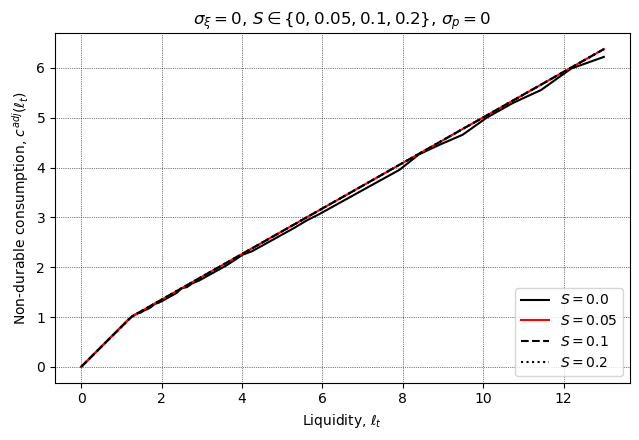

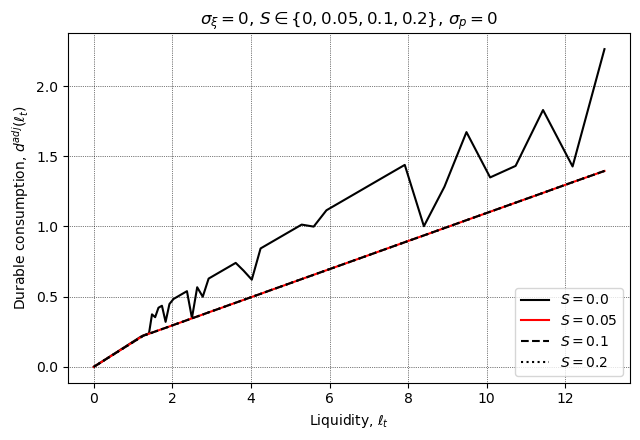

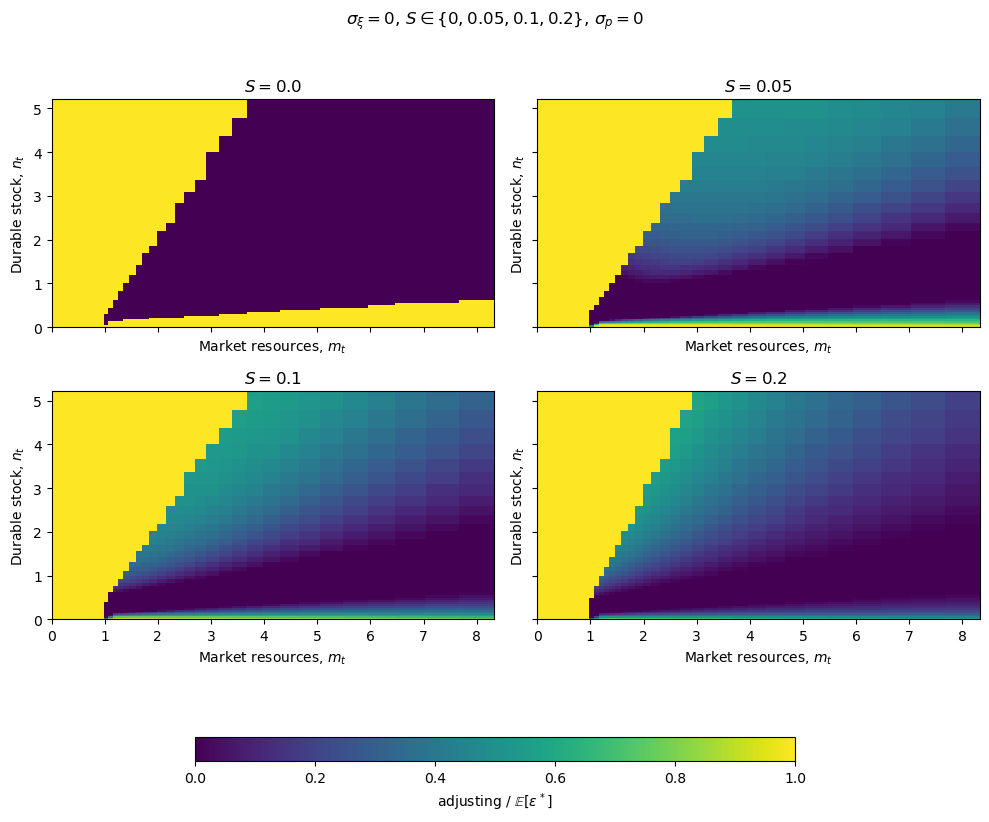

In [8]:
base_search = copy.deepcopy(durable_defaults)
base_search["sigma_xi"] = 0.0
base_search["PriceShkStd"] = 0.0
base_search["TasteShkCount"] = 1
base_search["PriceShkCount"] = 1

S_vals = [0.0, 0.05, 0.1, 0.2]
search_models = []
for S in S_vals:
    print(f"Solving SearchCost={S}...")
    search_models.append(solve_variant(base_search, SearchCost=S))

search_labels = [rf"$S = {S}$" for S in S_vals]
title = r"$\sigma_{\xi} = 0$, $S \in \{0, 0.05, 0.1, 0.2\}$, $\sigma_{p} = 0$"
plot_adjuster_policies(search_models, search_labels, t, title, "Search")
plot_ss_heatmaps(search_models, search_labels, t, "Search_Ss.pdf", suptitle=title)


### PriceModel (no tasteshock, search)
- Price standard deviation = 0, 0.05, 0.1, 0.2

Plot:
- non-durable consumption function of adjuster (all 4 in one)
- durable consumption function of the adjuster (all 4 in one)
- Ss structure (similar to DurableModel_One_Period.ipynb) (4 subplots)

Solving PriceShkStd=0.0...


c:\Users\adria\anaconda3\envs\DCEGM_Search_env\lib\site-packages\HARK\rewards.py:40: RuntimeWarning: divide by zero encountered in reciprocal
  return c ** (1.0 - rho) / (1.0 - rho)
c:\Users\adria\OneDrive - Johns Hopkins\Github\AMonninger\DCEGM_Search\Code\DurableModel.py:353: RuntimeWarning: divide by zero encountered in power
  * C ** (self.alpha * (1.0 - self.CRRA) - 1.0)
c:\Users\adria\OneDrive - Johns Hopkins\Github\AMonninger\DCEGM_Search\Code\DurableModel.py:360: RuntimeWarning: divide by zero encountered in power
  * (C ** (self.alpha * (1.0 - self.CRRA)))


Solving PriceShkStd=0.05...
Solving PriceShkStd=0.1...
Solving PriceShkStd=0.2...


c:\Users\adria\anaconda3\envs\DCEGM_Search_env\lib\site-packages\HARK\rewards.py:161: RuntimeWarning: divide by zero encountered in reciprocal
  return ((1.0 - rho) * u) ** (1 / (1.0 - rho))


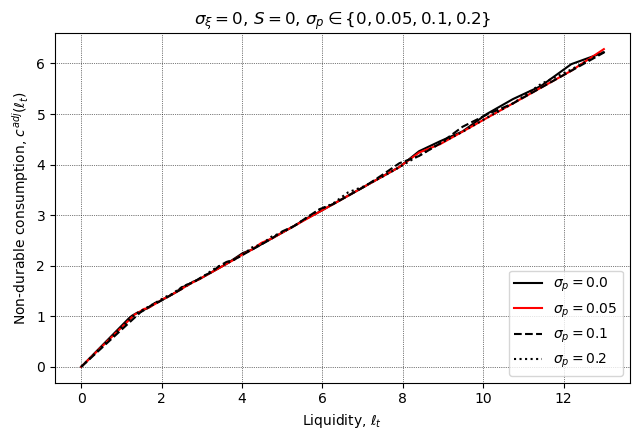

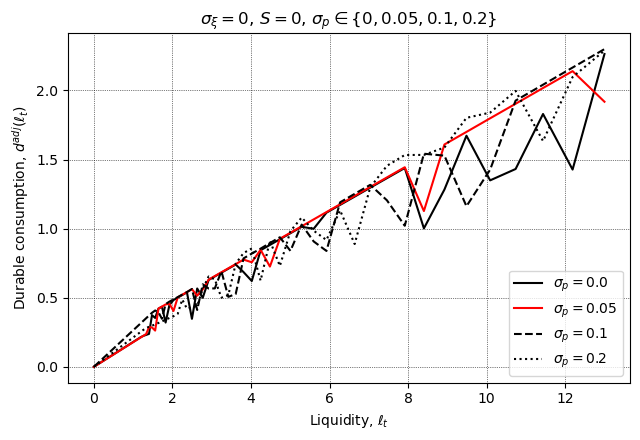

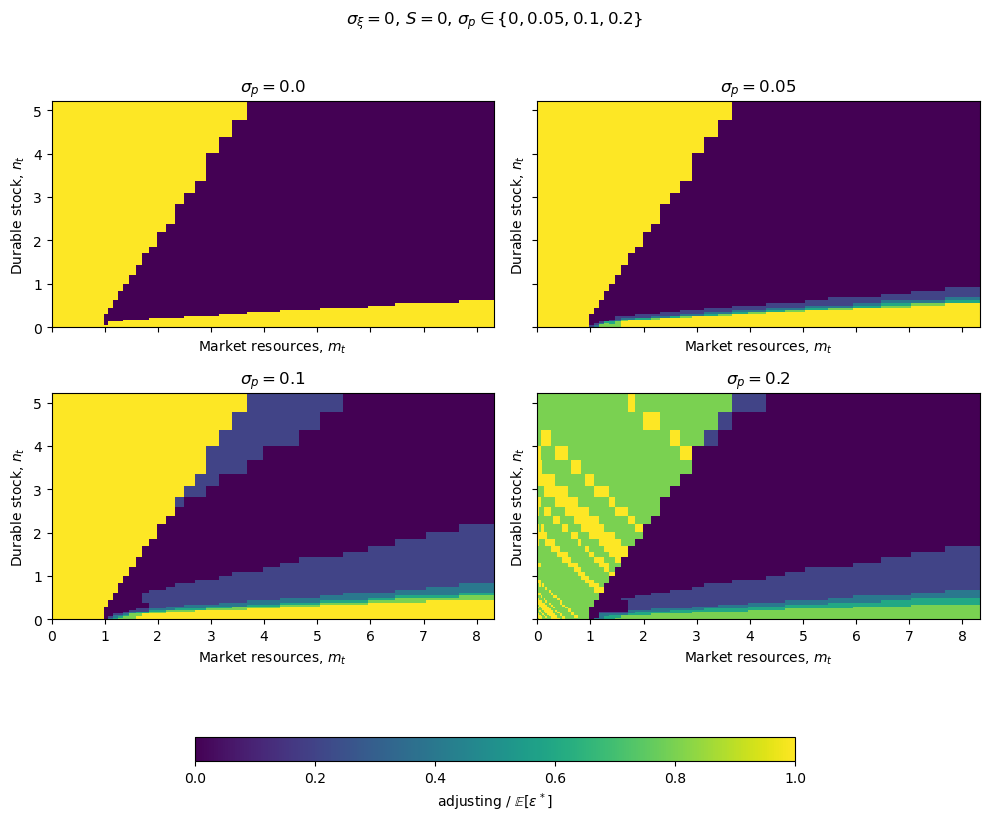

In [9]:
base_price = copy.deepcopy(durable_defaults)
base_price["sigma_xi"] = 0.0
base_price["SearchCost"] = 0.0
base_price["TasteShkCount"] = 1

p_stds = [0.0, 0.05, 0.1, 0.2]
price_models = []
for ps in p_stds:
    print(f"Solving PriceShkStd={ps}...")
    price_models.append(
        solve_variant(
            base_price,
            PriceShkStd=ps,
            PriceShkCount=1 if ps == 0.0 else base_price["PriceShkCount"],
        )
    )

price_labels = [rf"$\sigma_{{p}} = {ps}$" for ps in p_stds]
title = r"$\sigma_{\xi} = 0$, $S = 0$, $\sigma_{p} \in \{0, 0.05, 0.1, 0.2\}$"
plot_adjuster_policies(price_models, price_labels, t, title, "PriceStd")
plot_ss_heatmaps(price_models, price_labels, t, "PriceStd_Ss.pdf", suptitle=title)


### Price (no tasteshock, search)
- Price standard deviation = 0.1
- Price shock points = 1, 5, 13, 21

Plot:
- non-durable consumption function of adjuster (all 4 in one)
- durable consumption function of the adjuster (all 4 in one)
- Ss structure (similar to DurableModel_One_Period.ipynb) (4 subplots)

Solving PriceShkCount=1...


c:\Users\adria\anaconda3\envs\DCEGM_Search_env\lib\site-packages\HARK\rewards.py:40: RuntimeWarning: divide by zero encountered in reciprocal
  return c ** (1.0 - rho) / (1.0 - rho)
c:\Users\adria\OneDrive - Johns Hopkins\Github\AMonninger\DCEGM_Search\Code\DurableModel.py:353: RuntimeWarning: divide by zero encountered in power
  * C ** (self.alpha * (1.0 - self.CRRA) - 1.0)
c:\Users\adria\OneDrive - Johns Hopkins\Github\AMonninger\DCEGM_Search\Code\DurableModel.py:360: RuntimeWarning: divide by zero encountered in power
  * (C ** (self.alpha * (1.0 - self.CRRA)))


Solving PriceShkCount=5...
Solving PriceShkCount=13...
Solving PriceShkCount=21...


c:\Users\adria\anaconda3\envs\DCEGM_Search_env\lib\site-packages\HARK\rewards.py:161: RuntimeWarning: divide by zero encountered in reciprocal
  return ((1.0 - rho) * u) ** (1 / (1.0 - rho))


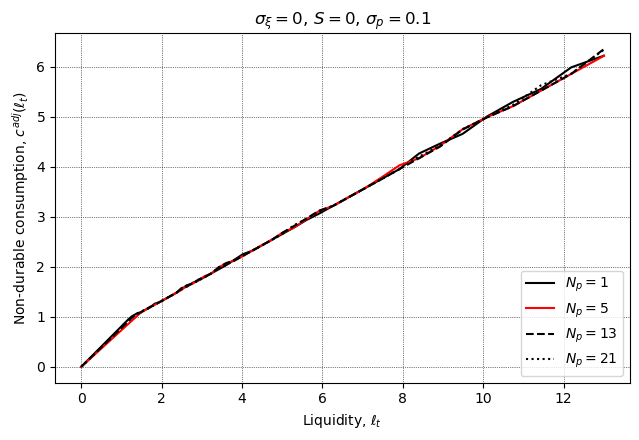

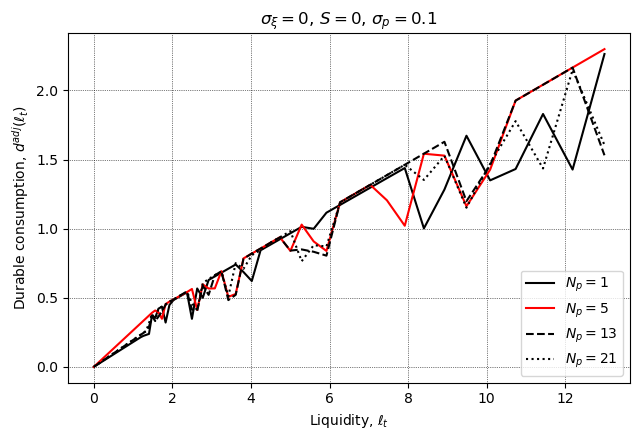

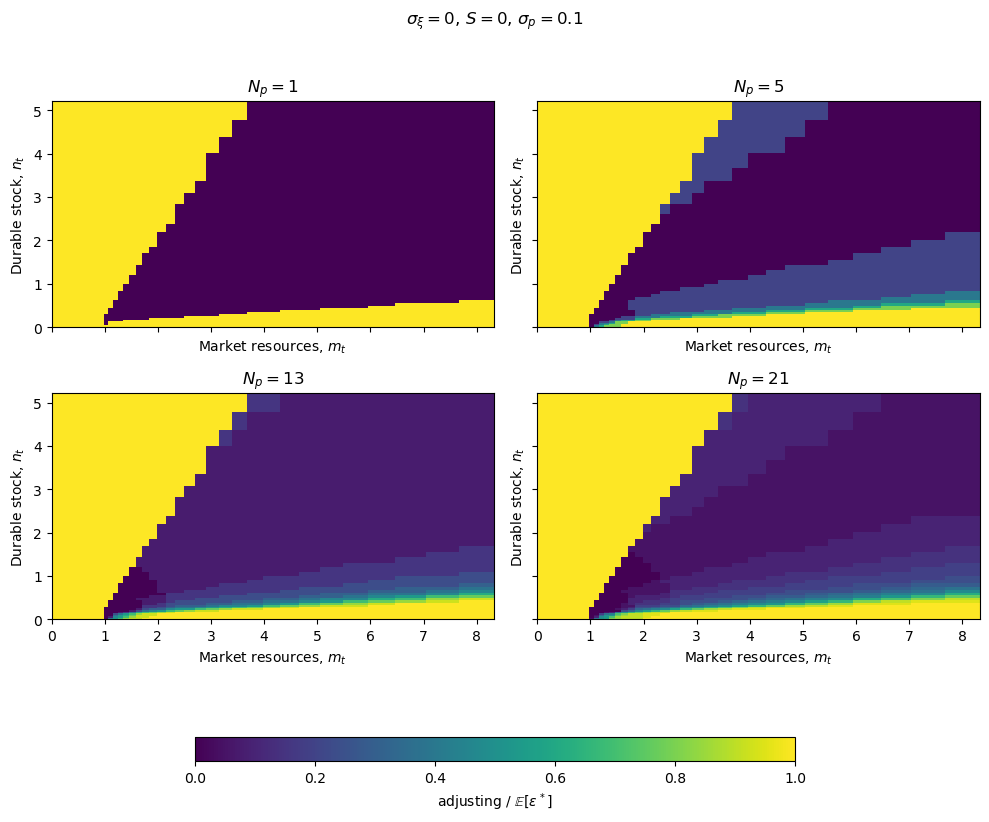

All durable figures done in 0:01:12.656306
Saved under C:\Users\adria\OneDrive - Johns Hopkins\Github\AMonninger\DCEGM_Search\Figures\DurableModel


In [10]:
base_pcount = copy.deepcopy(durable_defaults)
base_pcount["sigma_xi"] = 0.0
base_pcount["SearchCost"] = 0.0
base_pcount["TasteShkCount"] = 1
base_pcount["PriceShkStd"] = 0.1

p_counts = [1, 5, 13, 21]
pcount_models = []
for nc in p_counts:
    print(f"Solving PriceShkCount={nc}...")
    pcount_models.append(solve_variant(base_pcount, PriceShkCount=nc))

pcount_labels = [rf"$N_p = {nc}$" for nc in p_counts]
title = r"$\sigma_{\xi} = 0$, $S = 0$, $\sigma_{p} = 0.1$"
plot_adjuster_policies(pcount_models, pcount_labels, t, title, "PriceCount")
plot_ss_heatmaps(pcount_models, pcount_labels, t, "PriceCount_Ss.pdf", suptitle=title)

elapsed = time.time() - start_time
print("All durable figures done in", str(datetime.timedelta(seconds=elapsed)))
print("Saved under", FIG_DIR.resolve())


### Price and Search Model (no taste)
- Price standard deviation = 0, 0.1
- Search = 0, 0.1

Plot:
- non-durable consumption function of adjuster (all 4 in one)
- durable consumption function of the adjuster (all 4 in one)
- Ss structure (similar to DurableModel_One_Period.ipynb) (4 subplots)

c:\Users\adria\anaconda3\envs\DCEGM_Search_env\lib\site-packages\HARK\rewards.py:40: RuntimeWarning: divide by zero encountered in reciprocal
  return c ** (1.0 - rho) / (1.0 - rho)
c:\Users\adria\OneDrive - Johns Hopkins\Github\AMonninger\DCEGM_Search\Code\DurableModel.py:353: RuntimeWarning: divide by zero encountered in power
  * C ** (self.alpha * (1.0 - self.CRRA) - 1.0)
c:\Users\adria\OneDrive - Johns Hopkins\Github\AMonninger\DCEGM_Search\Code\DurableModel.py:360: RuntimeWarning: divide by zero encountered in power
  * (C ** (self.alpha * (1.0 - self.CRRA)))
c:\Users\adria\OneDrive - Johns Hopkins\Github\AMonninger\DCEGM_Search\Code\utility.py:541: RuntimeWarning: divide by zero encountered in power
  return shocks[0] ** (-CRRA) * (


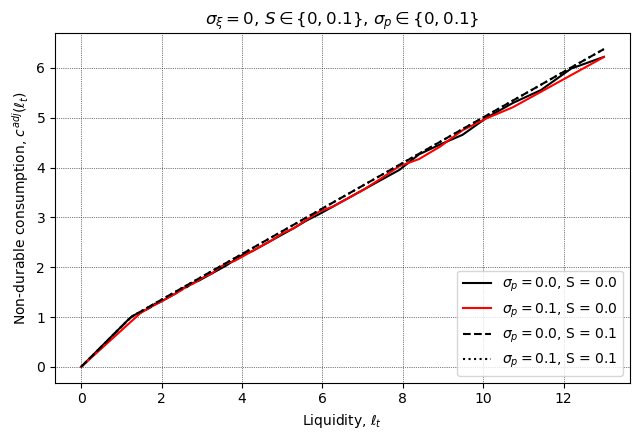

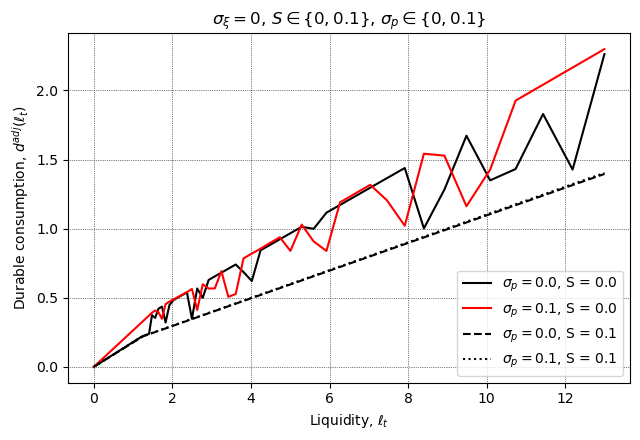

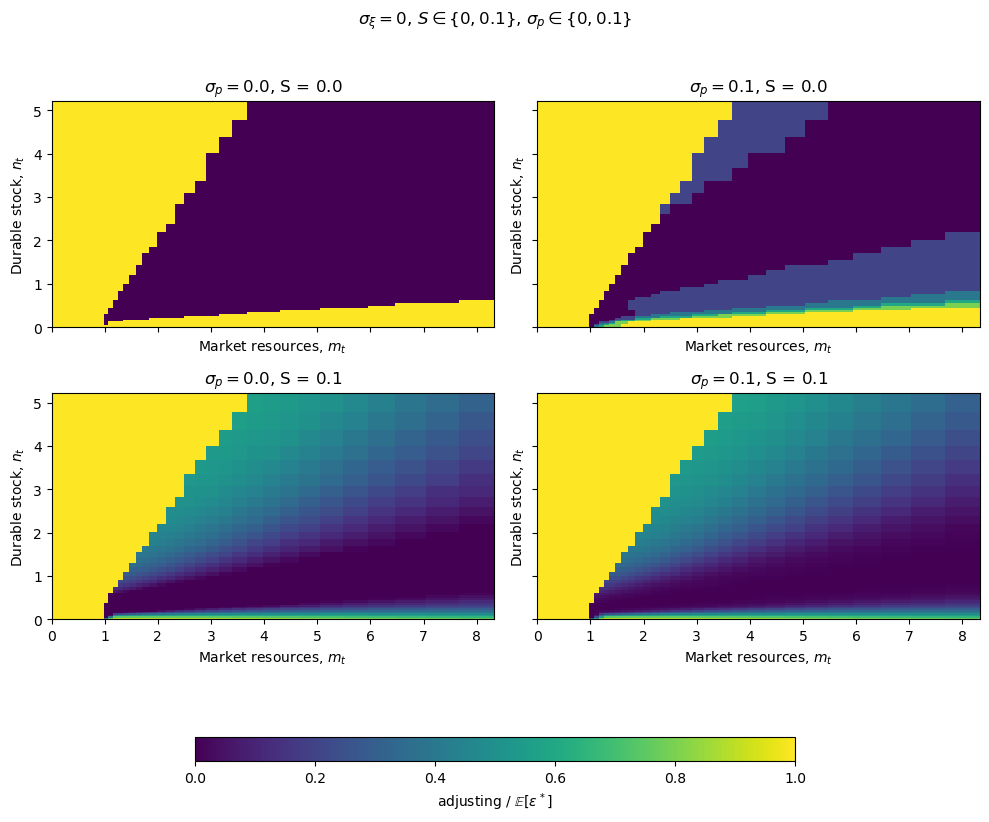

In [11]:
base_price_search = copy.deepcopy(durable_defaults)
base_price_search["sigma_xi"] = 0.0
base_price_search["SearchCost"] = 0.0
base_price_search["TasteShkCount"] = 1

price_search_models = []
price_search_models.append(
        solve_variant(
            base_price_search,
            PriceShkStd=0.0,
            PriceShkCount=1,
            SearchCost = 0.0
        )
    )

price_search_models.append(
        solve_variant(
            base_price_search,
            PriceShkStd=0.1,
            PriceShkCount=5,
            SearchCost = 0.0
        )
    )

price_search_models.append(
        solve_variant(
            base_price_search,
            PriceShkStd=0.0,
            PriceShkCount=1,
            SearchCost = 0.1
        )
    )

price_search_models.append(
        solve_variant(
            base_price_search,
            PriceShkStd=0.1,
            PriceShkCount=5,
            SearchCost = 0.1
        )
    )


price_search_labels = ['$\\sigma_{p} = 0.0$, S = 0.0',
 '$\\sigma_{p} = 0.1$, S = 0.0',
 '$\\sigma_{p} = 0.0$, S = 0.1',
 '$\\sigma_{p} = 0.1$, S = 0.1']
 
title = r"$\sigma_{\xi} = 0$, $S \in \{0, 0.1\}$, $\sigma_{p} \in \{0, 0.1\}$"
plot_adjuster_policies(price_search_models, price_search_labels, t, title, "PriceStd_Search")
plot_ss_heatmaps(price_search_models, price_search_labels, t, "PriceStd_Search_Ss.pdf", suptitle=title)
